# Car Price Prediction Using Machine Learning

## Task 3: Regression Analysis

**Objective:** To develop a machine learning regression model that predicts the selling price of a used car based on features such as brand, car age, kilometers driven, fuel type, transmission, engine capacity, mileage, and maximum power.

**Technologies Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Jupyter Notebook.

**Dataset:** CarDekho Used Car Dataset.

**Target Variable:** `selling_price`

**Machine Learning Approach:** Supervised learning using regression algorithms.

## 1. Import Libraries and Load Dataset

In this step, we import the necessary Python libraries for data manipulation, visualization, machine learning, and model evaluation. We then load the CarDekho CSV dataset into a Pandas DataFrame and inspect the first few records and dataset dimensions.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.inspection import permutation_importance
import joblib

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("All libraries imported successfully.")

All libraries imported successfully.


In [5]:
# Change the filename if your dataset has a different name.
file_path = "cardekho.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (8128, 12)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0



Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats']


## 2. Data Cleaning and Preprocessing

Data cleaning improves dataset quality and prepares it for machine learning. This step standardizes column names and categorical values, removes duplicate records, converts numeric columns into appropriate data types, handles invalid values, and removes records with missing target values or manufacturing years.

Missing values in predictor features will be handled later using a preprocessing pipeline.

In [6]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   str    
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   str    
 5   seller_type         8128 non-null   str    
 6   transmission        8128 non-null   str    
 7   owner               8128 non-null   str    
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   str    
 11  seats               7907 non-null   float64
dtypes: float64(3), int64(3), str(6)
memory usage: 1.2 MB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,8128,2058,Maruti Swift Dzire VDI,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,8128.0,NaN,NaN,NaN,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,NaN,NaN,NaN,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,NaN,NaN,NaN,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,8128,3,Individual,6766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8128,2,Manual,7078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage(km/ltr/kg),7907.0,NaN,NaN,NaN,19.418783,4.037145,0.0,16.78,19.3,22.32,42.0
engine,7907.0,NaN,NaN,NaN,1458.625016,503.916303,624.0,1197.0,1248.0,1582.0,3604.0



Missing values in each column:
name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64

Number of duplicate rows: 1202


In [7]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Convert common dataset column names to consistent names.
column_mapping = {
    "car_name": "name",
    "car": "name",
    "carname": "name",
    "model": "name",
    "manufacturing_year": "year",
    "sellingprice": "selling_price",
    "presentprice": "present_price",
    "kms_driven": "km_driven",
    "km_drivers": "km_driven",
    "fuel_type": "fuel",
    "seller_type": "seller_type",
    "transmission_type": "transmission",
    "owner": "owner"
}

df = df.rename(columns=column_mapping)

print("Standardized columns:")
print(df.columns.tolist())

Standardized columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage_km_ltr_kg', 'engine', 'max_power', 'seats']


In [8]:
# Remove exact duplicate rows.
df = df.drop_duplicates().copy()

# Standardize text columns.
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Standardize common categorical columns.
for col in ["fuel", "transmission", "seller_type", "name"]:
    if col in df.columns:
        df[col] = df[col].str.lower()

# Convert numeric fields safely.
numeric_candidates = [
    "year", "selling_price", "present_price",
    "km_driven", "owner", "mileage", "engine", "seats"
]

for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Selling price and year are essential.
required_columns = ["year", "selling_price"]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(
        f"Required columns not found: {missing_columns}. "
        f"Check your CSV columns: {df.columns.tolist()}"
    )

# A missing target or year cannot be used to train this model.
df = df.dropna(subset=["selling_price", "year"]).copy()

# Remove impossible or invalid values.
df = df[
    (df["selling_price"] > 0) &
    (df["year"] <= datetime.now().year)
].copy()

if "km_driven" in df.columns:
    df = df[df["km_driven"].isna() | (df["km_driven"] >= 0)].copy()

print("Shape after cleaning:", df.shape)
print("\nRemaining missing values:")
print(df.isnull().sum())

Shape after cleaning: (6926, 12)

Remaining missing values:
name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                6926
mileage_km_ltr_kg     208
engine                208
max_power             205
seats                 208
dtype: int64


## 3. Feature Engineering

Feature engineering creates useful variables from existing dataset columns.

- **Car Age:** Calculated by subtracting the manufacturing year from the current year.
- **Brand:** Extracted from the car name using the first word.

These features help the regression models identify patterns between vehicle characteristics and resale prices.

In [9]:
current_year = datetime.now().year

df["car_age"] = current_year - df["year"]

if "name" in df.columns:
    df["brand"] = (
        df["name"]
        .fillna("unknown")
        .str.strip()
        .str.split()
        .str[0]
        .str.title()
    )
else:
    df["brand"] = "Unknown"

print("Feature engineering completed.")

display(df[[
    c for c in ["name", "brand", "year", "car_age",
                "km_driven", "selling_price"]
    if c in df.columns
]].head(10))

Feature engineering completed.


,name,brand,year,car_age,km_driven,selling_price
0,maruti swift dzire vdi,Maruti,2014,12,145500,450000
1,skoda rapid 1.5 tdi ambition,Skoda,2014,12,120000,370000
2,honda city 2017-2020 exi,Honda,2006,20,140000,158000
3,hyundai i20 sportz diesel,Hyundai,2010,16,127000,225000
4,maruti swift vxi bsiii,Maruti,2007,19,120000,130000
5,hyundai xcent 1.2 vtvt e plus,Hyundai,2017,9,45000,440000
6,maruti wagon r lxi duo bsiii,Maruti,2007,19,175000,96000
7,maruti 800 dx bsii,Maruti,2001,25,5000,45000
8,toyota etios vxd,Toyota,2011,15,90000,350000
9,ford figo diesel celebration edition,Ford,2013,13,169000,200000


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution of selling prices and relationships between vehicle features.

The following visualizations are generated:

1. Selling-price distribution histogram.
2. Box plot of selling price by fuel type.
3. Scatter plot of car age versus selling price.
4. Correlation heatmap of numerical variables.

These visualizations help identify patterns, possible outliers, and relationships that may influence car prices.

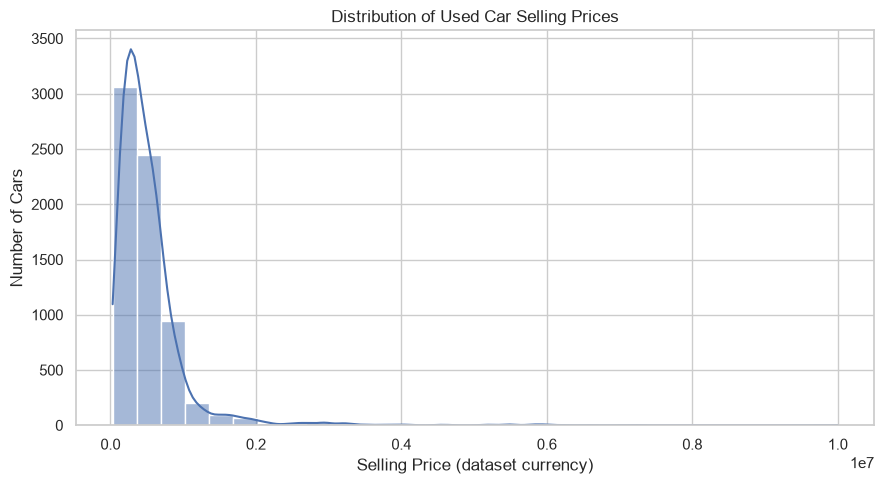

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="selling_price",
    bins=30,
    kde=True
)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (dataset currency)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

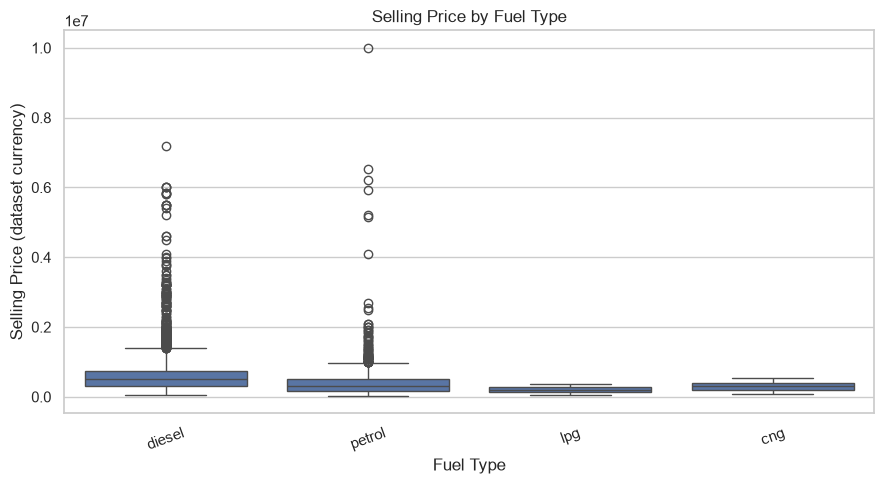

In [11]:
if "fuel" in df.columns:
    plt.figure(figsize=(9, 5))

    sns.boxplot(data=df, x="fuel", y="selling_price")

    plt.title("Selling Price by Fuel Type")
    plt.xlabel("Fuel Type")
    plt.ylabel("Selling Price (dataset currency)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
else:
    print("Fuel column not available.")

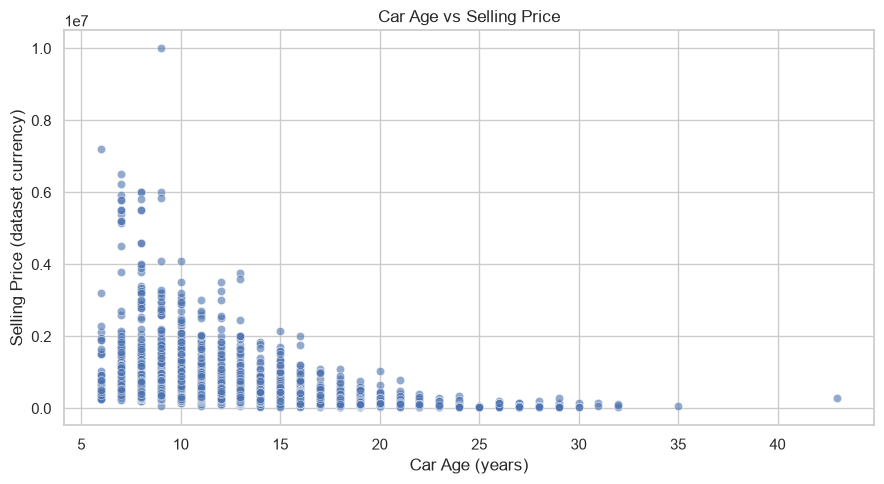

In [12]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="car_age",
    y="selling_price",
    alpha=0.6
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (years)")
plt.ylabel("Selling Price (dataset currency)")
plt.tight_layout()
plt.show()

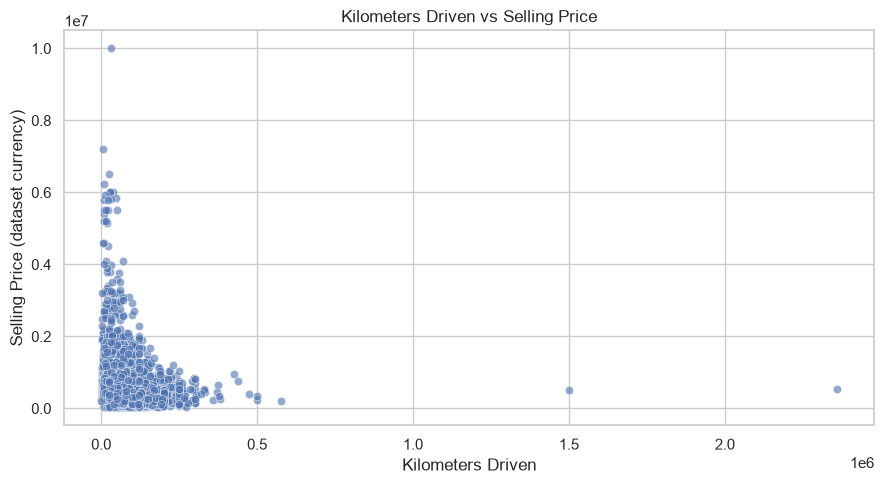

In [13]:
if "km_driven" in df.columns:
    plt.figure(figsize=(9, 5))

    sns.scatterplot(
        data=df,
        x="km_driven",
        y="selling_price",
        alpha=0.6
    )

    plt.title("Kilometers Driven vs Selling Price")
    plt.xlabel("Kilometers Driven")
    plt.ylabel("Selling Price (dataset currency)")
    plt.tight_layout()
    plt.show()

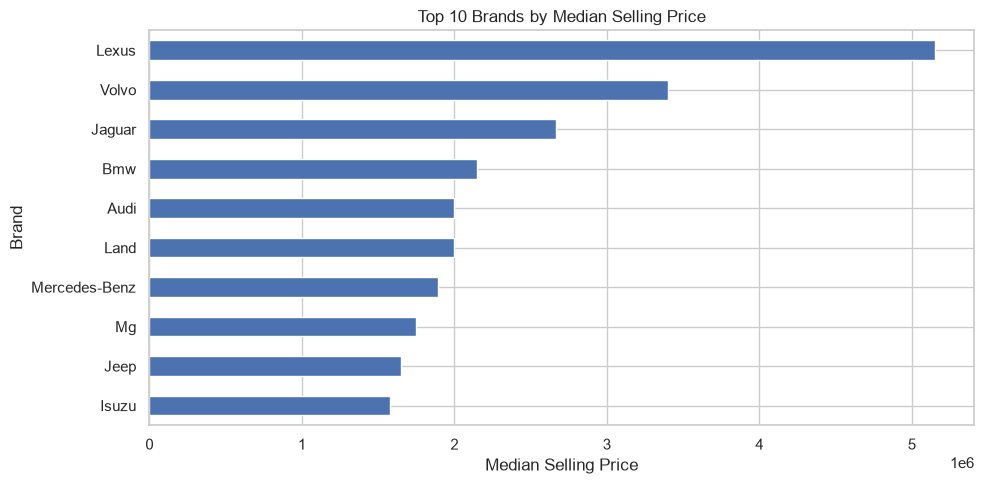

In [14]:
brand_prices = (
    df.groupby("brand")["selling_price"]
    .median()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
brand_prices.sort_values().plot(kind="barh")

plt.title("Top 10 Brands by Median Selling Price")
plt.xlabel("Median Selling Price")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

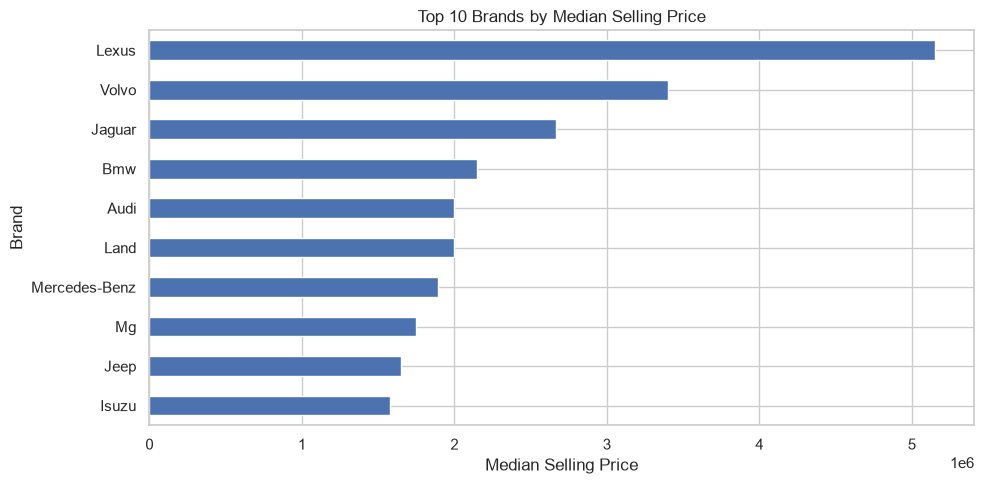

In [15]:
brand_prices = (
    df.groupby("brand")["selling_price"]
    .median()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
brand_prices.sort_values().plot(kind="barh")

plt.title("Top 10 Brands by Median Selling Price")
plt.xlabel("Median Selling Price")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

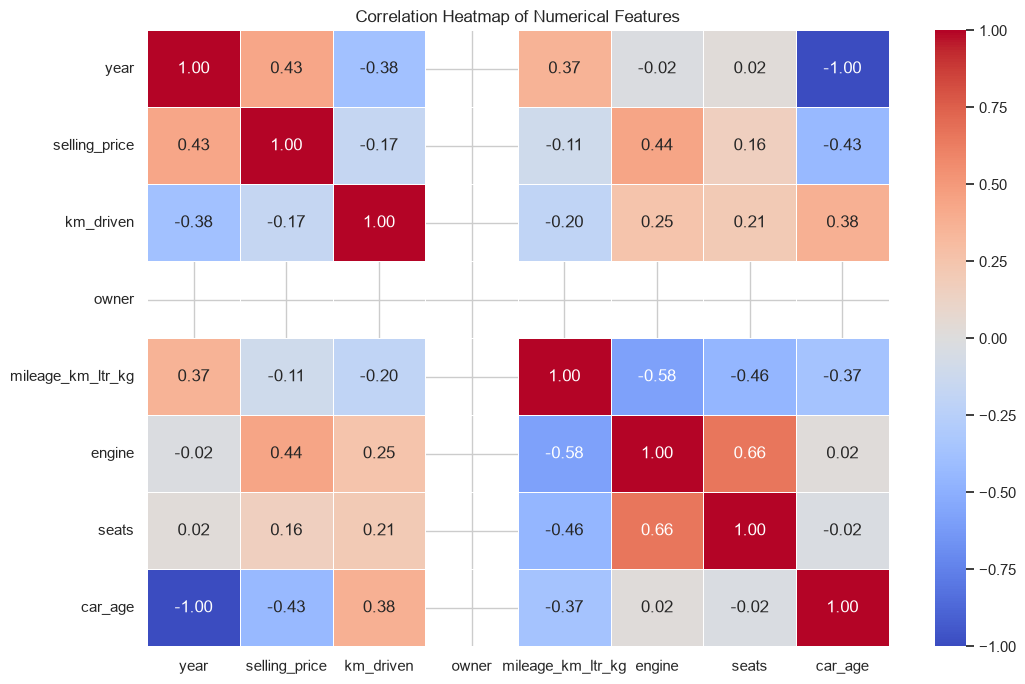

In [16]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(11, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

## 5. Feature Selection and Train-Test Split

The target variable is `selling_price`. Predictor features include brand, car age, kilometers driven, fuel type, seller type, transmission, owner information, mileage, engine capacity, maximum power, and number of seats.

The dataset is divided into:

- **80% training data:** Used to train the regression models.
- **20% testing data:** Used to evaluate predictions on unseen records.

A fixed random state ensures reproducible splitting.

In [17]:
# Candidate predictors; only columns that exist will be used.
candidate_features = [
    "brand",
    "car_age",
    "km_driven",
    "fuel",
    "transmission",
    "seller_type",
    "owner",
    "present_price",
    "mileage",
    "engine",
    "seats"
]

features = [c for c in candidate_features if c in df.columns]
target = "selling_price"

if not features:
    raise ValueError("No usable predictor features were found.")

# Keep target separate from predictors.
X = df[features].copy()
y = df[target].copy()

# Remove columns that are completely empty.
empty_features = X.columns[X.isna().all()].tolist()
X = X.drop(columns=empty_features)

features = X.columns.tolist()

print("Selected features:", features)
print("Target variable:", target)
print("Number of rows:", len(X))
print("Features removed because they were entirely empty:", empty_features)

Selected features: ['brand', 'car_age', 'km_driven', 'fuel', 'transmission', 'seller_type', 'engine', 'seats']
Target variable: selling_price
Number of rows: 6926
Features removed because they were entirely empty: ['owner']


## 6. Categorical Encoding and Missing Value Handling

Machine learning algorithms require numerical inputs. One-Hot Encoding converts categorical variables into numerical indicator features.

Numerical missing values are imputed using the median, while categorical missing values are imputed using the most frequent category. Numerical variables are standardized using `StandardScaler`.

The preprocessing pipeline is fitted on the training data to reduce data leakage and ensure consistent processing of unseen records.

In [18]:
# Detect numerical and categorical columns.
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = [
    c for c in X.columns if c not in numeric_features
]

# Numerical preprocessing.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each column type.
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split before fitting preprocessing or training any model.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Training rows: 5540
Testing rows: 1386
Numerical features: ['car_age', 'km_driven', 'engine', 'seats']
Categorical features: ['brand', 'fuel', 'transmission', 'seller_type']


## 7. Training Regression Models

Three supervised regression algorithms are trained and evaluated:

1. **Linear Regression:** Establishes a baseline by modelling linear relationships between features and selling prices.
2. **Random Forest Regressor:** Combines multiple decision trees to capture nonlinear patterns.
3. **Gradient Boosting Regressor:** Builds successive decision trees to improve prediction performance.

All models use the same training and testing split and the same preprocessing pipeline for a fair comparison.

In [19]:
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

results = []
trained_models = {}

for name, regressor in models.items():

    # Preprocessing followed by regression.
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    model.fit(X_train, y_train)

    # Predict prices on unseen test data.
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = model

    print(f"\n{name}")
    print(f"MAE      : {mae:,.2f}")
    print(f"RMSE     : {rmse:,.2f}")
    print(f"R2 Score : {r2:.4f}")

results_df = pd.DataFrame(results).sort_values(
    by="MAE", ascending=True
).reset_index(drop=True)

print("\nFinal model comparison:")
display(results_df.round(4))


Linear Regression
MAE      : 147,056.36
RMSE     : 276,260.76
R2 Score : 0.6520

Random Forest
MAE      : 91,088.28
RMSE     : 186,504.71
R2 Score : 0.8414

Gradient Boosting
MAE      : 104,902.90
RMSE     : 189,126.02
R2 Score : 0.8369

Final model comparison:


,Model,MAE,RMSE,R2 Score
0,Random Forest,91088.2838,186504.7081,0.8414
1,Gradient Boosting,104902.8982,189126.0188,0.8369
2,Linear Regression,147056.3588,276260.7640,0.6520


## 8. Model Evaluation and Comparison

The models are evaluated using three regression metrics:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted prices. Lower values are better.
- **Root Mean Squared Error (RMSE):** Measures prediction error while penalizing larger errors more strongly. Lower values are better.
- **R² Score:** Measures how well the model explains variation in selling prices. Higher values are generally better.

A comparison table and bar charts are generated to assess model performance. The model with the lowest test-set MAE is selected as the initial best-performing model.

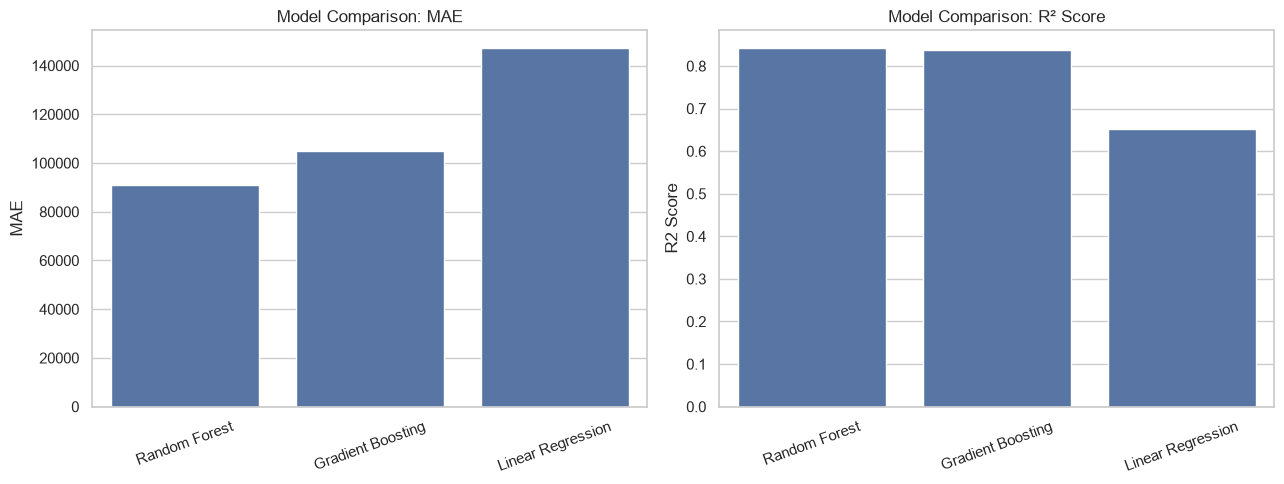

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("Model Comparison: MAE")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=results_df, x="Model", y="R2 Score", ax=axes[1])
axes[1].set_title("Model Comparison: R² Score")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [21]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on lowest MAE:", best_model_name)
print("MAE:", round(results_df.iloc[0]["MAE"], 2))
print("RMSE:", round(results_df.iloc[0]["RMSE"], 2))
print("R2 Score:", round(results_df.iloc[0]["R2 Score"], 4))

Best model based on lowest MAE: Random Forest
MAE: 91088.28
RMSE: 186504.71
R2 Score: 0.8414


## 9. Actual vs. Predicted Selling Prices

This visualization compares actual selling prices with prices predicted by the selected model.

A reference line represents perfect predictions. Points closer to this line indicate more accurate estimates, while points farther away indicate larger prediction errors.

This plot provides a visual assessment of how closely the model's predictions match the actual selling prices.

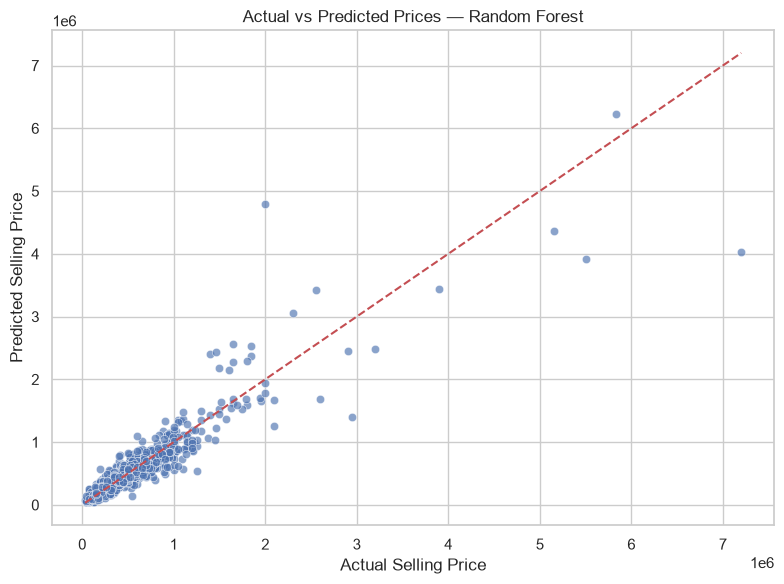

In [22]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=best_predictions,
    alpha=0.65
)

# Reference line for perfect predictions.
lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())

plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title(f"Actual vs Predicted Prices — {best_model_name}")

plt.tight_layout()
plt.show()

## 10. Feature Importance Analysis

Permutation importance is used to estimate the contribution of each input feature to the selected model's predictive performance.

The method shuffles one feature at a time and measures the resulting change in prediction error. A larger positive importance value indicates that the feature is useful for prediction.

The results help identify which vehicle characteristics contribute most to accurate selling-price estimates. Feature importance indicates predictive usefulness, not causation.

,Feature,Importance
1,car_age,151415.1415
6,engine,141026.3795
0,brand,27209.5516
4,transmission,18552.7462
7,seats,8750.0266
2,km_driven,8082.8701
3,fuel,3294.9693
5,seller_type,336.9775


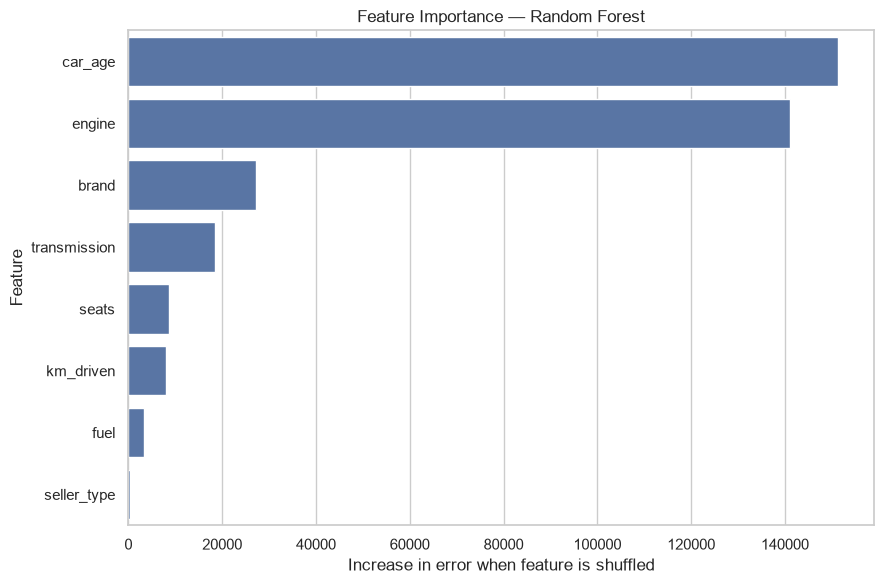

In [24]:
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title(f"Feature Importance — {best_model_name}")
plt.xlabel("Increase in error when feature is shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 11. Sample Car Price Prediction

The trained model is tested using a sample record from the test dataset.

The actual selling price is compared with the predicted price, and the absolute prediction error is calculated. This demonstrates how the trained regression model estimates the selling price of an individual used car.

In [25]:
 # Use an actual test row as an example.
sample_car = X_test.iloc[[0]]

predicted_price = best_model.predict(sample_car)[0]
actual_price = y_test.iloc[0]

print("Input car details:")
display(sample_car)

print(f"Actual selling price:    {actual_price:,.2f}")
print(f"Predicted selling price: {predicted_price:,.2f}")
print(f"Absolute error:          {abs(actual_price - predicted_price):,.2f}")

Input car details:


,brand,car_age,km_driven,fuel,transmission,seller_type,engine,seats
8077,Toyota,17,250000,diesel,manual,individual,2494.0,7.0


Actual selling price:    550,000.00
Predicted selling price: 604,967.49
Absolute error:          54,967.49


In [26]:
example_values = {
    "brand": "Maruti",
    "car_age": 5,
    "km_driven": 50000,
    "fuel": "petrol",
    "transmission": "manual",
    "seller_type": "individual",
    "owner": 0,
    "present_price": 6.0,
    "mileage": 20.0,
    "engine": 1200,
    "seats": 5
}

custom_car = pd.DataFrame(
    [{feature: example_values.get(feature, np.nan)
      for feature in features}],
    columns=features
)

custom_prediction = best_model.predict(custom_car)[0]

print("Custom car details:")
display(custom_car)

print(f"Estimated selling price: {custom_prediction:,.2f}")
print("Note: Price units match those used in the training dataset.")

Custom car details:


,brand,car_age,km_driven,fuel,transmission,seller_type,engine,seats
0,Maruti,5,50000,petrol,manual,individual,1200,5


Estimated selling price: 471,206.84
Note: Price units match those used in the training dataset.


## 12. Saving the Trained Model

The selected model and its associated metadata are saved using Joblib. The saved model can be loaded in a future Python session to make predictions without retraining the algorithms.

The preprocessing steps are included in the model pipeline, ensuring that new input records receive the same transformations used during training.

In [27]:
model_bundle = {
    "model": best_model,
    "features": features,
    "target": target,
    "best_model_name": best_model_name,
    "dataset_columns": df.columns.tolist()
}

joblib.dump(model_bundle, "car_price_prediction_model.joblib")

print("Model saved successfully!")
print("File: car_price_prediction_model.joblib")

Model saved successfully!
File: car_price_prediction_model.joblib


In [28]:
loaded_bundle = joblib.load("car_price_prediction_model.joblib")

loaded_model = loaded_bundle["model"]
loaded_features = loaded_bundle["features"]

print("Loaded model:", loaded_bundle["best_model_name"])
print("Expected features:", loaded_features)

Loaded model: Random Forest
Expected features: ['brand', 'car_age', 'km_driven', 'fuel', 'transmission', 'seller_type', 'engine', 'seats']


# 13. Conclusion

This project demonstrates the application of supervised machine learning regression techniques to used-car price prediction using the CarDekho dataset.

The dataset is cleaned and explored, relevant features are engineered, categorical variables are encoded, and three regression algorithms are trained and compared using MAE, RMSE, and R².

The final model is selected based on its evaluation results. Feature importance and actual-versus-predicted visualizations are used to understand its performance.

**Future Scope:** The project can be improved through hyperparameter tuning, cross-validation, additional vehicle features, larger datasets, and deployment as a web application.

**Final Results:** Add the actual evaluation metrics and selected model name obtained from the executed notebook.